In [ ]:
import pandas as pd

In [ ]:
from google.colab import files
files.upload()

In [1]:
!kaggle datasets download -d abc123/customer-sales-data

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata


In [2]:
!pip install -q kaggle

In [3]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [4]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)
os.rename('kaggle.json', '/root/.kaggle/kaggle.json')

os.chmod('/root/.kaggle/kaggle.json', 600)

print("Kaggle connected successfully!")

Kaggle connected successfully!


In [6]:
import pandas as pd

url = "https://raw.githubusercontent.com/akmand/datasets/master/Global%20Superstore%202006-2015.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.shape)

HTTPError: HTTP Error 404: Not Found

In [7]:
!kaggle datasets list -s "global superstore"

ref                                                       title                                                    size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------  -------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
anandaramg/global-superstore                              Global Superstore                                     3333751  2023-11-06 03:27:09.327000           8071         85                1  
fatihilhan/global-superstore-dataset                      Global Superstore Dataset                             3349507  2023-11-16 11:58:36.210000          31430        170                1  
abbas829/global-superstore-sales-dataset                  Global Superstore Sales Dataset                       2814050  2026-05-23 00:41:54.710000           4385         45                1  
ronysoliman/global-superstore-datas

In [8]:
!kaggle datasets download -d anandaramg/global-superstore

Dataset URL: https://www.kaggle.com/datasets/anandaramg/global-superstore
License(s): apache-2.0
100% 3.18M/3.18M [00:00<00:00, 158MB/s]



In [9]:
import zipfile
import os

zip_file = "global-superstore.zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("global_superstore")

print("Dataset extracted successfully!")
print(os.listdir("global_superstore"))

Dataset extracted successfully!
['Global Superstore.txt']


In [10]:
os.listdir("global_superstore")

['Global Superstore.txt']

In [11]:
file_path = "global_superstore/Global Superstore.txt"

with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
    for i in range(5):
        print(f.readline())

Category	City	Country	Customer ID	Customer Name	Discount	Market	记录数	Order Date	Order ID	Order Priority	Product ID	Product Name	Profit	Quantity	Region	Row ID	Sales	Segment	Ship Date	Ship Mode	Shipping Cost	State	Sub-Category	Year	Market2	weeknum

"Office Supplies"	"Los Angeles"	"United States"	"LS-172304"	"Lycoris Saunders"	0	"US"	1	2011-01-07 00:00:00.000	"CA-2011-130813"	"High"	"OFF-PA-10002005"	"Xerox 225"	9.3312	3	"West"	36624	19	"Consumer"	2011-01-09 00:00:00.000	"Second Class"	4.37	"California"	"Paper"	2011	"North America"	2

"Office Supplies"	"Los Angeles"	"United States"	"MV-174854"	"Mark Van Huff"	0	"US"	1	2011-01-21 00:00:00.000	"CA-2011-148614"	"Medium"	"OFF-PA-10002893"	"Wirebound Service Call Books, 5 1/2"" x 4"""	9.2928	2	"West"	37033	19	"Consumer"	2011-01-26 00:00:00.000	"Standard Class"	0.94	"California"	"Paper"	2011	"North America"	4

"Office Supplies"	"Los Angeles"	"United States"	"CS-121304"	"Chad Sievert"	0	"US"	1	2011-08-05 00:00:00.000	"CA-2011-118962"	"Medium"	"OF

In [12]:
import pandas as pd

file_path = "global_superstore/Global Superstore.txt"

df = pd.read_csv(
    file_path,
    sep="\t",
    encoding="utf-8",
    quotechar='"'
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 51290
Columns: 27


In [13]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Column names:
['Category', 'City', 'Country', 'Customer ID', 'Customer Name', 'Discount', 'Market', '记录数', 'Order Date', 'Order ID', 'Order Priority', 'Product ID', 'Product Name', 'Profit', 'Quantity', 'Region', 'Row ID', 'Sales', 'Segment', 'Ship Date', 'Ship Mode', 'Shipping Cost', 'State', 'Sub-Category', 'Year', 'Market2', 'weeknum']

Missing values:
Category          0
City              0
Country           0
Customer ID       0
Customer Name     0
Discount          0
Market            0
记录数               0
Order Date        0
Order ID          0
Order Priority    0
Product ID        0
Product Name      0
Profit            0
Quantity          0
Region            0
Row ID            0
Sales             0
Segment           0
Ship Date         0
Ship Mode         0
Shipping Cost     0
State             0
Sub-Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

Duplicate rows:
0

Data types:
Category           object
City               object
Count

In [14]:
categorical_columns = [
    "Category",
    "Market",
    "Order Priority",
    "Region",
    "Segment",
    "Ship Mode",
    "Sub-Category",
    "Market2"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts())


--- Category ---
Category
Office Supplies    31273
Technology         10141
Furniture           9876
Name: count, dtype: int64

--- Market ---
Market
APAC      11002
LATAM     10294
EU        10000
US         9994
EMEA       5029
Africa     4587
Canada      384
Name: count, dtype: int64

--- Order Priority ---
Order Priority
Medium      29433
High        15501
Critical     3932
Low          2424
Name: count, dtype: int64

--- Region ---
Region
Central           11117
South              6645
EMEA               5029
North              4785
Africa             4587
Oceania            3487
West               3203
Southeast Asia     3129
East               2848
North Asia         2338
Central Asia       2048
Caribbean          1690
Canada              384
Name: count, dtype: int64

--- Segment ---
Segment
Consumer       26518
Corporate      15429
Home Office     9343
Name: count, dtype: int64

--- Ship Mode ---
Ship Mode
Standard Class    30775
Second Class      10309
First Class        750

In [15]:
print("Numerical columns summary:")
print(df.describe().T)

Numerical columns summary:
                 count          mean           std       min       25%  \
Discount       51290.0      0.142908      0.212280     0.000      0.00   
记录数            51290.0      1.000000      0.000000     1.000      1.00   
Profit         51290.0     28.610982    174.340972 -6599.978      0.00   
Quantity       51290.0      3.476545      2.278766     1.000      2.00   
Row ID         51290.0  25645.500000  14806.291990     1.000  12823.25   
Sales          51290.0    246.498440    487.567175     0.000     31.00   
Shipping Cost  51290.0     26.375818     57.296810     0.002      2.61   
Year           51290.0   2012.777208      1.098931  2011.000   2012.00   
weeknum        51290.0     31.287112     14.429795     1.000     20.00   

                    50%       75%        max  
Discount           0.00      0.20      0.850  
记录数                1.00      1.00      1.000  
Profit             9.24     36.81   8399.976  
Quantity           3.00      5.00     14.000

In [16]:
print("Unique values in important numerical columns:")

for column in ["Discount", "Quantity", "Sales", "Profit", "Shipping Cost", "Year", "weeknum"]:
    print(f"\n--- {column} ---")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print("Unique values:", df[column].nunique())

Unique values in important numerical columns:

--- Discount ---
Minimum: 0.0
Maximum: 0.85
Unique values: 27

--- Quantity ---
Minimum: 1
Maximum: 14
Unique values: 14

--- Sales ---
Minimum: 0
Maximum: 22638
Unique values: 2246

--- Profit ---
Minimum: -6599.978
Maximum: 8399.976
Unique values: 24575

--- Shipping Cost ---
Minimum: 0.002
Maximum: 933.57
Unique values: 16877

--- Year ---
Minimum: 2011
Maximum: 2014
Unique values: 4

--- weeknum ---
Minimum: 1
Maximum: 53
Unique values: 53


In [17]:
zero_sales = df[df["Sales"] == 0]

print("Number of records with Sales = 0:", len(zero_sales))

print("\nZero-sales records:")
display(zero_sales)

Number of records with Sales = 0: 1

Zero-sales records:


,Category,City,Country,Customer ID,Customer Name,Discount,Market,记录数,Order Date,Order ID,...,Sales,Segment,Ship Date,Ship Mode,Shipping Cost,State,Sub-Category,Year,Market2,weeknum
46158,Office Supplies,Houston,United States,ZC-219104,Zuschuss Carroll,0.8,US,1,2014-06-20 00:00:00.000,US-2014-102288,...,0,Consumer,2014-06-24 00:00:00.000,Standard Class,0.01,Texas,Appliances,2014,North America,25


In [18]:
print(zero_sales[[
    "Order ID",
    "Product Name",
    "Quantity",
    "Sales",
    "Profit",
    "Shipping Cost",
    "Order Date"
]].head(20))

             Order ID                                       Product Name  \
46158  US-2014-102288  Hoover Replacement Belt for Commercial Guardsm...   

       Quantity  Sales  Profit  Shipping Cost               Order Date  
46158         1      0   -1.11           0.01  2014-06-20 00:00:00.000  


In [19]:
negative_profit = df[df["Profit"] < 0]

print("Records with negative profit:", len(negative_profit))
print("Percentage of records with negative profit:",
      round(len(negative_profit) / len(df) * 100, 2), "%")

print("\nMost negative profit records:")
display(
    negative_profit[
        ["Order ID", "Product Name", "Sales", "Discount", "Quantity", "Profit"]
    ].sort_values("Profit").head(10)
)

Records with negative profit: 12544
Percentage of records with negative profit: 24.46 %

Most negative profit records:


,Order ID,Product Name,Sales,Discount,Quantity,Profit
47074,CA-2013-108196,Cubify CubeX 3D Printer Double Head Print,4500,0.7,5,-6599.9780
29353,TU-2013-9400,"Motorola Smart Phone, Cordless",3085,0.6,12,-4088.3760
47388,US-2014-168116,Cubify CubeX 3D Printer Triple Head Print,8000,0.5,4,-3839.9904
46422,CA-2011-169019,GBC DocuBind P400 Electric Binding System,2178,0.8,8,-3701.8928
47414,CA-2014-134845,Lexmark MX611dhe Monochrome Laser Printer,2550,0.7,5,-3399.9800
39499,IT-2013-3695467,"Hoover Stove, White",3400,0.5,12,-3059.8200
30168,ID-2013-12295,"Apple Smart Phone, Full Size",3499,0.5,11,-3009.4350
46876,US-2014-122714,Ibico EPK-21 Electric Binding System,1890,0.8,5,-2929.4845
29652,LH-2014-5390,"Barricks Conference Table, Rectangular",2171,0.7,8,-2750.2800
47070,CA-2012-147830,Cubify CubeX 3D Printer Double Head Print,1800,0.7,2,-2639.9912


In [20]:
print("Order Date type:", df["Order Date"].dtype)
print("Ship Date type:", df["Ship Date"].dtype)

print("\nSample Order Dates:")
print(df["Order Date"].head())

print("\nSample Ship Dates:")
print(df["Ship Date"].head())

Order Date type: object
Ship Date type: object

Sample Order Dates:
0    2011-01-07 00:00:00.000
1    2011-01-21 00:00:00.000
2    2011-08-05 00:00:00.000
3    2011-08-05 00:00:00.000
4    2011-09-29 00:00:00.000
Name: Order Date, dtype: object

Sample Ship Dates:
0    2011-01-09 00:00:00.000
1    2011-01-26 00:00:00.000
2    2011-08-09 00:00:00.000
3    2011-08-09 00:00:00.000
4    2011-10-03 00:00:00.000
Name: Ship Date, dtype: object


In [21]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print("Order Date type:", df["Order Date"].dtype)
print("Ship Date type:", df["Ship Date"].dtype)

Order Date type: datetime64[ns]
Ship Date type: datetime64[ns]


In [22]:
invalid_dates = df[df["Ship Date"] < df["Order Date"]]

print("Records where Ship Date is before Order Date:", len(invalid_dates))

Records where Ship Date is before Order Date: 0


In [23]:
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

print("Shipping duration calculated successfully!")

print("\nShipping Days summary:")
print(df["Shipping Days"].describe())

Shipping duration calculated successfully!

Shipping Days summary:
count    51290.000000
mean         3.969370
std          1.729437
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max          7.000000
Name: Shipping Days, dtype: float64


In [24]:
text_columns = df.select_dtypes(include="object").columns

print("Checking for leading/trailing spaces...\n")

for column in text_columns:
    spaces = df[column].astype(str).str.strip().ne(df[column].astype(str)).sum()

    if spaces > 0:
        print(f"{column}: {spaces} values have extra spaces")

Checking for leading/trailing spaces...



In [25]:
print("Checking for capitalization inconsistencies...\n")

for column in text_columns:
    original_unique = df[column].nunique()
    normalized_unique = df[column].astype(str).str.strip().str.lower().nunique()

    if original_unique != normalized_unique:
        print(f"{column}:")
        print("Original unique values:", original_unique)
        print("After normalization:", normalized_unique)
        print()

Checking for capitalization inconsistencies...



In [26]:
order_counts = df["Order ID"].value_counts()

print("Total unique Order IDs:", df["Order ID"].nunique())
print("Total rows:", len(df))

print("\nOrders appearing more than once:")
print((order_counts > 1).sum())

print("\nMaximum rows for a single Order ID:")
print(order_counts.max())

Total unique Order IDs: 25035
Total rows: 51290

Orders appearing more than once:
12778

Maximum rows for a single Order ID:
14


In [27]:
order_product_counts = df.groupby(
    ["Order ID", "Product ID"]
).size()

duplicate_order_products = order_product_counts[
    order_product_counts > 1
]

print("Repeated Order ID + Product ID combinations:",
      len(duplicate_order_products))

print("\nMaximum occurrences of the same Order ID + Product ID:",
      order_product_counts.max())

Repeated Order ID + Product ID combinations: 38

Maximum occurrences of the same Order ID + Product ID: 2


In [28]:
duplicate_order_products = order_product_counts[
    order_product_counts > 1
]

duplicate_keys = duplicate_order_products.reset_index()[
    ["Order ID", "Product ID"]
]

duplicate_records = df.merge(
    duplicate_keys,
    on=["Order ID", "Product ID"],
    how="inner"
).sort_values(["Order ID", "Product ID"])

print("Number of records to inspect:", len(duplicate_records))

display(
    duplicate_records[
        [
            "Order ID",
            "Product ID",
            "Product Name",
            "Order Date",
            "Customer Name",
            "Quantity",
            "Sales",
            "Discount",
            "Profit"
        ]
    ]
)

Number of records to inspect: 76


,Order ID,Product ID,Product Name,Order Date,Customer Name,Quantity,Sales,Discount,Profit
46,AG-2014-4840,TEC-MEM-10002524,"Memorex Mouse, USB",2014-08-20,Cynthia Delaney,2,57,0.0,10.7400
47,AG-2014-4840,TEC-MEM-10002524,"Memorex Mouse, USB",2014-08-20,Cynthia Delaney,2,57,0.0,10.7400
4,CA-2012-103135,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",2012-07-24,Shirley Schmidt,9,135,0.0,62.1414
5,CA-2012-103135,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",2012-07-24,Shirley Schmidt,6,90,0.0,41.4276
0,CA-2013-129714,OFF-PA-10001970,Xerox 1881,2013-09-02,Adam Bellavance,2,25,0.0,11.5432
...,...,...,...,...,...,...,...,...,...
71,US-2011-150119,FUR-CH-10002965,Global Leather Highback Executive Chair with P...,2011-04-23,Laurel Beltran,2,281,0.3,-12.0588
72,US-2013-123750,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,2013-04-16,Ross Baird,7,409,0.2,76.6395
73,US-2013-123750,TEC-AC-10004659,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,2013-04-16,Ross Baird,5,292,0.2,54.7425
15,UZ-2014-7970,OFF-IBI-10003191,"Ibico 3-Hole Punch, Durable",2014-02-17,Valerie Dominguez,1,32,0.0,11.8200


In [29]:
duplicate_exact = duplicate_records[
    duplicate_records.duplicated(keep=False)
]

print("Completely identical records among these:", len(duplicate_exact))

display(
    duplicate_exact[
        [
            "Order ID",
            "Product ID",
            "Product Name",
            "Order Date",
            "Customer Name",
            "Quantity",
            "Sales",
            "Discount",
            "Profit"
        ]
    ]
)

Completely identical records among these: 0


,Order ID,Product ID,Product Name,Order Date,Customer Name,Quantity,Sales,Discount,Profit


In [30]:
print("Unique values in 记录数:")
print(df["记录数"].unique())

print("\nValue counts:")
print(df["记录数"].value_counts())

Unique values in 记录数:
[1]

Value counts:
记录数
1    51290
Name: count, dtype: int64


In [31]:
numeric_columns = [
    "Sales",
    "Profit",
    "Discount",
    "Quantity",
    "Shipping Cost"
]

print("Outlier check using IQR:\n")

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}:")
    print(f"  Lower bound: {lower_bound:.2f}")
    print(f"  Upper bound: {upper_bound:.2f}")
    print(f"  Outliers: {len(outliers)}")
    print()

Outlier check using IQR:

Sales:
  Lower bound: -299.00
  Upper bound: 581.00
  Outliers: 5655

Profit:
  Lower bound: -55.22
  Upper bound: 92.03
  Outliers: 9755

Discount:
  Lower bound: -0.30
  Upper bound: 0.50
  Outliers: 4172

Quantity:
  Lower bound: -2.50
  Upper bound: 9.50
  Outliers: 877

Shipping Cost:
  Lower bound: -30.15
  Upper bound: 57.21
  Outliers: 5909



In [32]:
print("Negative value check:\n")

for column in ["Sales", "Quantity", "Discount", "Shipping Cost"]:
    negative_count = (df[column] < 0).sum()
    print(f"{column}: {negative_count} negative values")

Negative value check:

Sales: 0 negative values
Quantity: 0 negative values
Discount: 0 negative values
Shipping Cost: 0 negative values


In [33]:
import numpy as np

numeric_columns = [
    "Discount",
    "Profit",
    "Quantity",
    "Row ID",
    "Sales",
    "Shipping Cost",
    "Year",
    "weeknum",
    "Shipping Days"
]

print("NaN and infinite value check:\n")

for column in numeric_columns:
    nan_count = df[column].isna().sum()
    infinite_count = np.isinf(df[column]).sum()

    print(f"{column}: NaN = {nan_count}, Infinite = {infinite_count}")

NaN and infinite value check:

Discount: NaN = 0, Infinite = 0
Profit: NaN = 0, Infinite = 0
Quantity: NaN = 0, Infinite = 0
Row ID: NaN = 0, Infinite = 0
Sales: NaN = 0, Infinite = 0
Shipping Cost: NaN = 0, Infinite = 0
Year: NaN = 0, Infinite = 0
weeknum: NaN = 0, Infinite = 0
Shipping Days: NaN = 0, Infinite = 0


In [34]:
df_clean = df.copy()

print("Clean dataset copy created!")
print("Original rows:", len(df))
print("Clean dataset rows:", len(df_clean))
print("Original columns:", len(df.columns))
print("Clean dataset columns:", len(df_clean.columns))

Clean dataset copy created!
Original rows: 51290
Clean dataset rows: 51290
Original columns: 28
Clean dataset columns: 28


In [35]:
df_clean = df_clean.drop(columns=["记录数"])

print("Redundant column removed successfully!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nRemaining columns:")
print(df_clean.columns.tolist())

Redundant column removed successfully!
Rows: 51290
Columns: 27

Remaining columns:
['Category', 'City', 'Country', 'Customer ID', 'Customer Name', 'Discount', 'Market', 'Order Date', 'Order ID', 'Order Priority', 'Product ID', 'Product Name', 'Profit', 'Quantity', 'Region', 'Row ID', 'Sales', 'Segment', 'Ship Date', 'Ship Mode', 'Shipping Cost', 'State', 'Sub-Category', 'Year', 'Market2', 'weeknum', 'Shipping Days']


In [36]:
df_clean["Sales_Zero_Flag"] = df_clean["Sales"] == 0

print("Sales = 0 records:", df_clean["Sales_Zero_Flag"].sum())
print("Total records:", len(df_clean))

print("\nFlagged record:")
display(
    df_clean[df_clean["Sales_Zero_Flag"]][
        ["Order ID", "Product ID", "Product Name",
         "Quantity", "Sales", "Profit", "Discount",
         "Sales_Zero_Flag"]
    ]
)

Sales = 0 records: 1
Total records: 51290

Flagged record:


,Order ID,Product ID,Product Name,Quantity,Sales,Profit,Discount,Sales_Zero_Flag
46158,US-2014-102288,OFF-AP-10002906,Hoover Replacement Belt for Commercial Guardsm...,1,0,-1.11,0.8,True


In [37]:
 Sales = 0 records: 1
Total records: 51290

Flagged record:




    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }





      Order ID
      Product ID
      Product Name
      Quantity
      Sales
      Profit
      Discount
      Sales_Zero_Flag




      46158
      US-2014-102288
      OFF-AP-10002906
      Hoover Replacement Belt for Commercial Guardsm...
      1
      0
      -1.11
      0.8
      True















    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }



      const buttonEl =
        document.querySelector('#df-49a53e95-e12e-4df6-911a-db18ffb55c8c button.colab-df-convert');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      async function convertToInteractive(key) {
        const element = document.querySelector('#df-49a53e95-e12e-4df6-911a-db18ffb55c8c');
        const dataTable =
          await google.colab.kernel.invokeFunction('convertToInteractive',
                                                    [key], {});
        if (!dataTable) return;

        const docLinkHtml = 'Like what you see? Visit the ' +
          '<a target="_blank" href=https://colab.research.google.com/notebooks/data_table.ipynb>data table notebook</a>'
          + ' to learn more about interactive tables.';
        element.innerHTML = '';
        dataTable['output_type'] = 'display_data';
        await google.colab.output.renderOutput(dataTable, element);
        const docLink = document.createElement('div');
        docLink.innerHTML = docLinkHtml;
        element.appendChild(docLink);
      }








SyntaxError: invalid decimal literal (31394269.py, line 63)

In [38]:
df_clean["Sales_Zero_Flag"] = df_clean["Sales"] == 0

print("Sales = 0 records:", df_clean["Sales_Zero_Flag"].sum())
print("Total records:", len(df_clean))

print("\nFlagged record:")

display(
    df_clean[df_clean["Sales_Zero_Flag"]][
        [
            "Order ID",
            "Product ID",
            "Product Name",
            "Quantity",
            "Sales",
            "Profit",
            "Discount",
            "Sales_Zero_Flag"
        ]
    ]
)

Sales = 0 records: 1
Total records: 51290

Flagged record:


,Order ID,Product ID,Product Name,Quantity,Sales,Profit,Discount,Sales_Zero_Flag
46158,US-2014-102288,OFF-AP-10002906,Hoover Replacement Belt for Commercial Guardsm...,1,0,-1.11,0.8,True


In [39]:
df_clean["Negative_Profit_Flag"] = df_clean["Profit"] < 0

print("Negative profit records:",
      df_clean["Negative_Profit_Flag"].sum())

print(
    "Percentage of records with negative profit:",
    round(df_clean["Negative_Profit_Flag"].mean() * 100, 2),
    "%"
)

Negative profit records: 12544
Percentage of records with negative profit: 24.46 %


In [40]:
print("FINAL VALIDATION")
print("=" * 40)

print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nMissing values:", df_clean.isnull().sum().sum())

print("Exact duplicate rows:", df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

FINAL VALIDATION
Rows: 51290
Columns: 29

Missing values: 0
Exact duplicate rows: 0

Data types:
Category                        object
City                            object
Country                         object
Customer ID                     object
Customer Name                   object
Discount                       float64
Market                          object
Order Date              datetime64[ns]
Order ID                        object
Order Priority                  object
Product ID                      object
Product Name                    object
Profit                         float64
Quantity                         int64
Region                          object
Row ID                           int64
Sales                            int64
Segment                         object
Ship Date               datetime64[ns]
Ship Mode                       object
Shipping Cost                  float64
State                           object
Sub-Category                    object
Year  

In [41]:
output_file = "global_superstore_cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", output_file)

import os
print("File size:", round(os.path.getsize(output_file) / (1024 * 1024), 2), "MB")

Cleaned dataset saved successfully!
File name: global_superstore_cleaned.csv
File size: 12.75 MB


In [42]:
print("BEFORE vs AFTER CLEANING")
print("=" * 45)

print("\nOriginal dataset:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCleaned dataset:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nChanges made:")
print("- Date columns converted to datetime")
print("- Added Shipping Days")
print("- Removed redundant 记录数 column")
print("- Added Sales_Zero_Flag")
print("- Added Negative_Profit_Flag")
print("- Missing values handled: 0 found")
print("- Exact duplicate rows handled: 0 found")
print("- Invalid dates: 0 found")
print("- Impossible negative values: 0 found")

print("\nRows removed:", df.shape[0] - df_clean.shape[0])
print("Columns removed:", df.shape[1] - df_clean.shape[1])
print("Columns added:", df_clean.shape[1] - df.shape[1])

BEFORE vs AFTER CLEANING

Original dataset:
Rows: 51290
Columns: 28

Cleaned dataset:
Rows: 51290
Columns: 29

Changes made:
- Date columns converted to datetime
- Added Shipping Days
- Removed redundant 记录数 column
- Added Sales_Zero_Flag
- Added Negative_Profit_Flag
- Missing values handled: 0 found
- Exact duplicate rows handled: 0 found
- Invalid dates: 0 found
- Impossible negative values: 0 found

Rows removed: 0
Columns removed: -1
Columns added: 1


In [43]:
cleaning_summary = {
    "Original Rows": len(df),
    "Cleaned Rows": len(df_clean),
    "Rows Removed": len(df) - len(df_clean),
    "Original Columns": len(df.columns),
    "Cleaned Columns": len(df_clean.columns),
    "Redundant Columns Removed": 1,
    "Missing Values": int(df_clean.isnull().sum().sum()),
    "Exact Duplicates": int(df_clean.duplicated().sum()),
    "Zero Sales Records Flagged": int(df_clean["Sales_Zero_Flag"].sum()),
    "Negative Profit Records Flagged": int(df_clean["Negative_Profit_Flag"].sum()),
    "Invalid Dates": 0
}

summary_df = pd.DataFrame(
    cleaning_summary.items(),
    columns=["Cleaning Metric", "Value"]
)

display(summary_df)

,Cleaning Metric,Value
0,Original Rows,51290
1,Cleaned Rows,51290
2,Rows Removed,0
3,Original Columns,28
4,Cleaned Columns,29
5,Redundant Columns Removed,1
6,Missing Values,0
7,Exact Duplicates,0
8,Zero Sales Records Flagged,1
9,Negative Profit Records Flagged,12544


In [44]:
def clean_global_superstore(file_path):
    """
    Reproducible data cleaning pipeline for Global Superstore dataset.
    """

    # 1. Load raw dataset
    data = pd.read_csv(
        file_path,
        sep="\t",
        encoding="utf-8",
        quotechar='"'
    )

    # 2. Convert date columns
    data["Order Date"] = pd.to_datetime(data["Order Date"])
    data["Ship Date"] = pd.to_datetime(data["Ship Date"])

    # 3. Create shipping duration
    data["Shipping Days"] = (
        data["Ship Date"] - data["Order Date"]
    ).dt.days

    # 4. Remove redundant constant column
    if "记录数" in data.columns:
        data = data.drop(columns=["记录数"])

    # 5. Create quality-control flags
    data["Sales_Zero_Flag"] = data["Sales"] == 0
    data["Negative_Profit_Flag"] = data["Profit"] < 0

    # 6. Return cleaned dataset
    return data


# Run the complete pipeline
df_pipeline = clean_global_superstore(
    "global_superstore/Global Superstore.txt"
)

print("Pipeline executed successfully!")
print("Rows:", df_pipeline.shape[0])
print("Columns:", df_pipeline.shape[1])
print("Missing values:", df_pipeline.isnull().sum().sum())
print("Exact duplicates:", df_pipeline.duplicated().sum())

Pipeline executed successfully!
Rows: 51290
Columns: 29
Missing values: 0
Exact duplicates: 0


In [45]:
print("PIPELINE VALIDATION")
print("=" * 45)

# Compare shape
print("Same number of rows:",
      len(df_pipeline) == len(df_clean))

print("Same number of columns:",
      len(df_pipeline.columns) == len(df_clean.columns))

# Compare column names
print("Same columns:",
      list(df_pipeline.columns) == list(df_clean.columns))

# Compare actual values
print("Same data:",
      df_pipeline.equals(df_clean))

PIPELINE VALIDATION
Same number of rows: True
Same number of columns: True
Same columns: True
Same data: True


Total Sales by Category:
Category
Technology         4744691
Furniture          4110884
Office Supplies    3787330
Name: Sales, dtype: int64


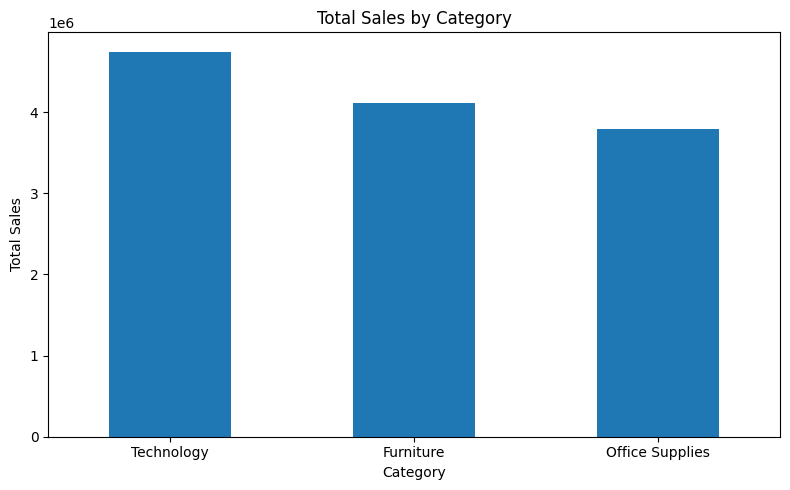

In [46]:
import matplotlib.pyplot as plt

category_sales = (
    df_pipeline.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Category:")
print(category_sales)

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Total Sales by Year:
Year
2011    2259511
2012    2677493
2013    3405860
2014    4300041
Name: Sales, dtype: int64


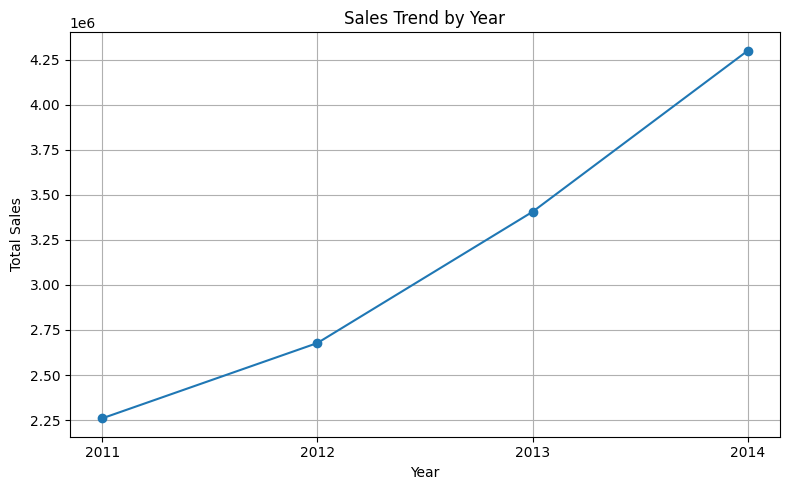

In [47]:
yearly_sales = (
    df_pipeline.groupby("Year")["Sales"]
    .sum()
)

print("Total Sales by Year:")
print(yearly_sales)

plt.figure(figsize=(8, 5))
yearly_sales.plot(kind="line", marker="o")

plt.title("Sales Trend by Year")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(yearly_sales.index)
plt.grid(True)
plt.tight_layout()
plt.show()

Total Profit by Category:
Category
Technology         663778.73318
Office Supplies    518473.83430
Furniture          285204.72380
Name: Profit, dtype: float64


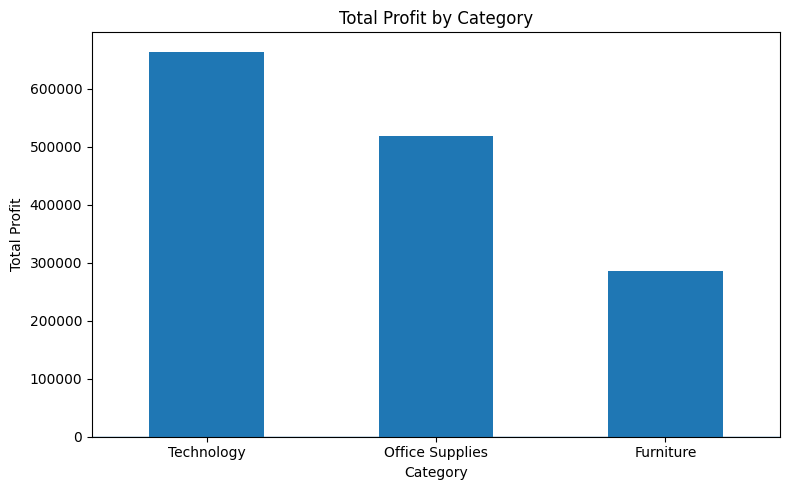

In [48]:
category_profit = (
    df_pipeline.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Profit by Category:")
print(category_profit)

plt.figure(figsize=(8, 5))
category_profit.plot(kind="bar")

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

Top 10 Most Profitable Products:
Product Name
Canon imageCLASS 2200 Advanced Copier                       25199.9280
Cisco Smart Phone, Full Size                                17238.5206
Motorola Smart Phone, Full Size                             17027.1130
Hoover Stove, Red                                           11807.9690
Sauder Classic Bookcase, Traditional                        10672.0730
Harbour Creations Executive Leather Armchair, Adjustable    10427.3260
Nokia Smart Phone, Full Size                                 9938.1955
Cisco Smart Phone, with Caller ID                            9786.6408
Nokia Smart Phone, with Caller ID                            9465.3257
Belkin Router, USB                                           8955.0180
Name: Profit, dtype: float64


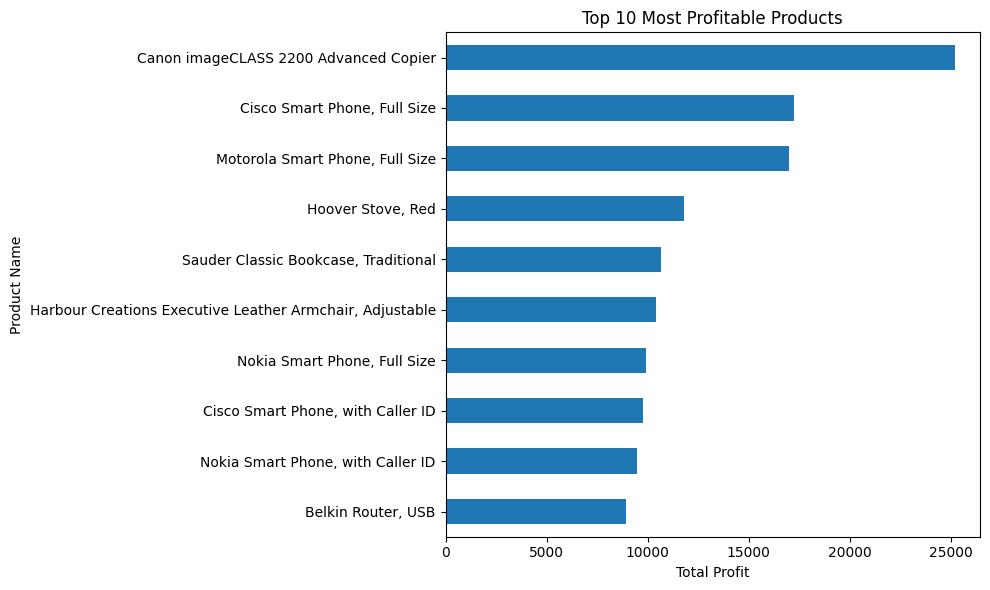

In [49]:
top_products = (
    df_pipeline.groupby("Product Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Most Profitable Products:")
print(top_products)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Most Profitable Products")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

Top 10 Loss-Making Products:
Product Name
Cubify CubeX 3D Printer Double Head Print                  -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                  -4589.9730
Motorola Smart Phone, Cordless                             -4447.0380
Cubify CubeX 3D Printer Triple Head Print                  -3839.9904
Bevis Round Table, Adjustable Height                       -3649.8940
Bevis Computer Table, Fully Assembled                      -3509.5638
Rogers Lockers, Blue                                       -2893.4908
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases   -2876.1156
Bevis Wood Table, with Bottom Storage                      -2782.5880
Lesro Training Table, Rectangular                          -2581.2834
Name: Profit, dtype: float64


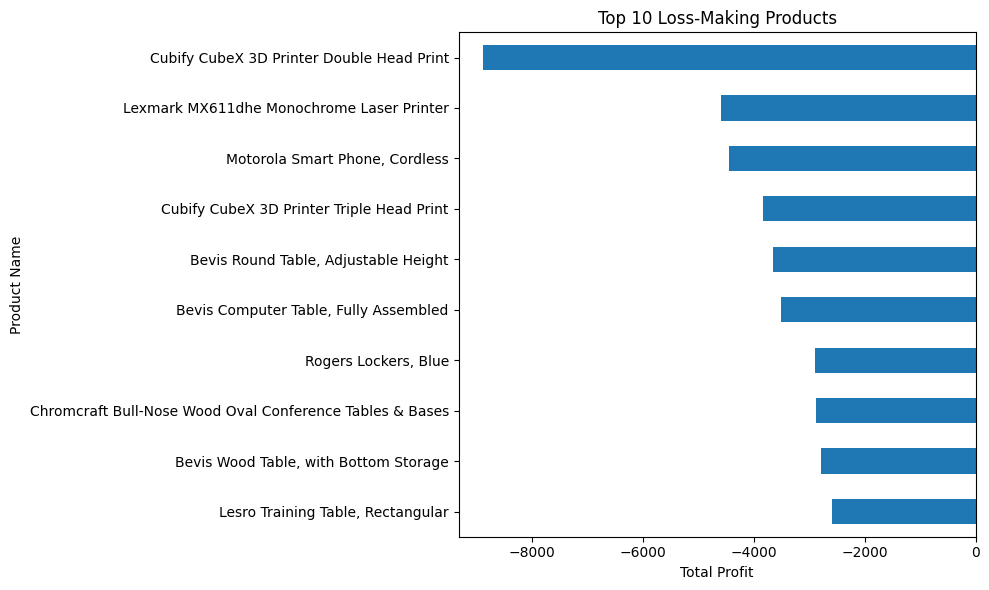

In [50]:
loss_products = (
    df_pipeline.groupby("Product Name")["Profit"]
    .sum()
    .sort_values()
    .head(10)
)

print("Top 10 Loss-Making Products:")
print(loss_products)

plt.figure(figsize=(10, 6))
loss_products.sort_values(ascending=False).plot(kind="barh")

plt.title("Top 10 Loss-Making Products")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

Average Profit by Discount:
    Discount       Profit
0      0.000    61.039514
1      0.002   125.762649
2      0.070   140.990022
3      0.100    63.683426
4      0.150    50.602409
5      0.170    38.317107
6      0.200    23.552594
7      0.202   -14.518847
8      0.250     4.043371
9      0.270    -4.317213
10     0.300   -57.899557
11     0.320   -88.560656
12     0.350  -116.144693
13     0.370   -78.462191
14     0.400   -45.246603
15     0.402  -109.908138
16     0.450   -41.610973
17     0.470   -42.982420
18     0.500   -97.140158
19     0.550  -315.067200
20     0.570  -526.129000
21     0.600   -81.732147
22     0.602  -213.279085
23     0.650  -365.997971
24     0.700  -104.339576
25     0.800  -122.203244
26     0.850 -1534.329000


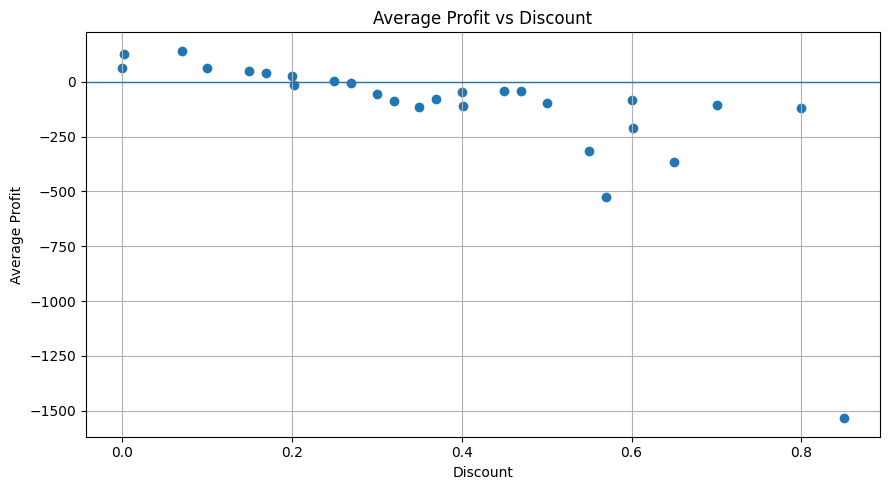

In [51]:
discount_profit = (
    df_pipeline.groupby("Discount")["Profit"]
    .mean()
    .reset_index()
)

print("Average Profit by Discount:")
print(discount_profit)

plt.figure(figsize=(9, 5))
plt.scatter(
    discount_profit["Discount"],
    discount_profit["Profit"]
)

plt.title("Average Profit vs Discount")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.axhline(0, linewidth=1)
plt.grid(True)
plt.tight_layout()
plt.show()

Shipping Performance by Ship Mode:
                count      mean  min  max
Ship Mode                                
Same Day         2701  0.037394    0    1
First Class      7505  2.181746    1    3
Second Class    10309  3.230187    2    5
Standard Class  30775  4.998018    4    7


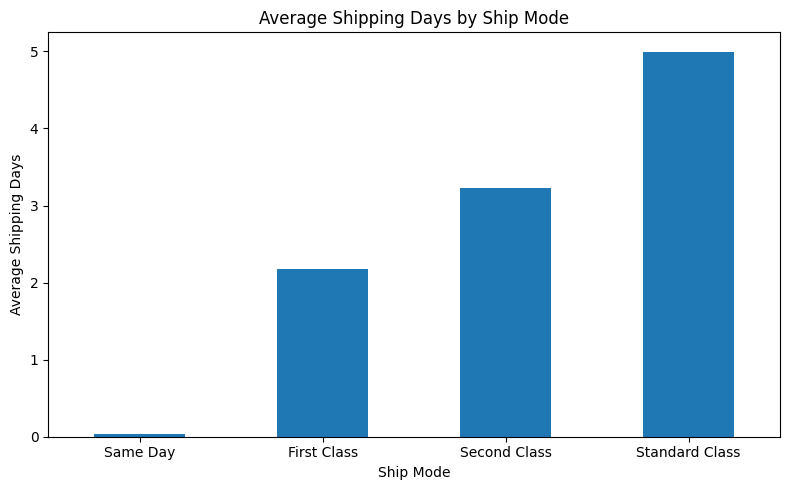

In [52]:
shipping_analysis = (
    df_pipeline.groupby("Ship Mode")["Shipping Days"]
    .agg(["count", "mean", "min", "max"])
    .sort_values("mean")
)

print("Shipping Performance by Ship Mode:")
print(shipping_analysis)

plt.figure(figsize=(8, 5))

shipping_analysis["mean"].plot(kind="bar")

plt.title("Average Shipping Days by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Total Sales by Region:
Region
Central           2822399
South             1600960
North             1248192
Oceania           1100207
Southeast Asia     884438
North Asia         848349
EMEA               806184
Africa             783776
Central Asia       752839
West               725514
East               678834
Caribbean          324281
Canada              66932
Name: Sales, dtype: int64


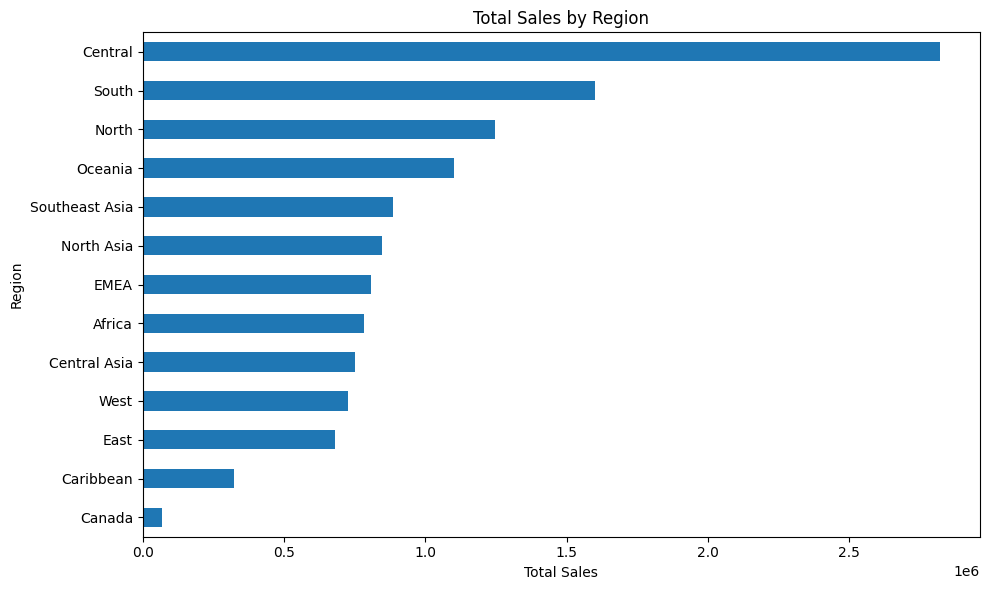

In [53]:
regional_sales = (
    df_pipeline.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Region:")
print(regional_sales)

plt.figure(figsize=(10, 6))

regional_sales.sort_values().plot(kind="barh")

plt.title("Total Sales by Region")
plt.xlabel("Total Sales")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

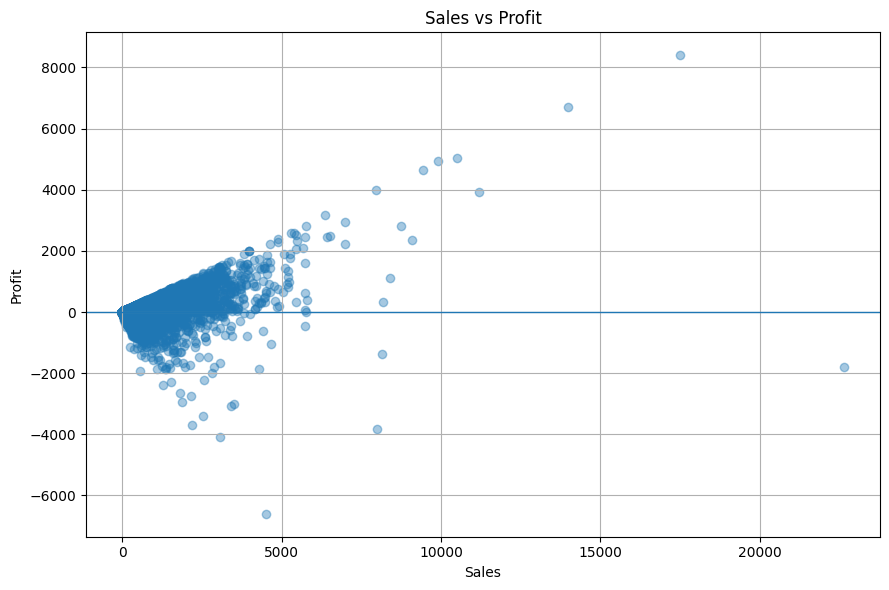

In [54]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df_pipeline["Sales"],
    df_pipeline["Profit"],
    alpha=0.4
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.axhline(0, linewidth=1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [55]:
print("=" * 55)
print("       FINAL DATA QUALITY REPORT")
print("=" * 55)

print("\n📊 DATASET SIZE")
print("Rows:", df_pipeline.shape[0])
print("Columns:", df_pipeline.shape[1])

print("\n🔍 MISSING VALUES")
missing_values = df_pipeline.isnull().sum().sum()
print("Total missing values:", missing_values)

print("\n🔁 DUPLICATES")
duplicates = df_pipeline.duplicated().sum()
print("Exact duplicate rows:", duplicates)

print("\n📅 DATE VALIDATION")
invalid_dates = (
    df_pipeline["Ship Date"] < df_pipeline["Order Date"]
).sum()
print("Invalid date sequences:", invalid_dates)

print("\n💰 NUMERICAL VALIDATION")
print("Negative Sales:", (df_pipeline["Sales"] < 0).sum())
print("Negative Quantity:", (df_pipeline["Quantity"] < 0).sum())
print("Negative Discount:", (df_pipeline["Discount"] < 0).sum())
print("Negative Shipping Cost:", (df_pipeline["Shipping Cost"] < 0).sum())

print("\n⚠️ QUALITY FLAGS")
print("Zero-sales records:", df_pipeline["Sales_Zero_Flag"].sum())
print("Negative-profit records:", df_pipeline["Negative_Profit_Flag"].sum())

print("\n🚚 SHIPPING")
print("Minimum shipping days:", df_pipeline["Shipping Days"].min())
print("Maximum shipping days:", df_pipeline["Shipping Days"].max())
print("Average shipping days:",
      round(df_pipeline["Shipping Days"].mean(), 2))

print("\n" + "=" * 55)
print("DATA QUALITY CHECK COMPLETED")
print("=" * 55)

       FINAL DATA QUALITY REPORT

📊 DATASET SIZE
Rows: 51290
Columns: 29

🔍 MISSING VALUES
Total missing values: 0

🔁 DUPLICATES
Exact duplicate rows: 0

📅 DATE VALIDATION
Invalid date sequences: 0

💰 NUMERICAL VALIDATION
Negative Sales: 0
Negative Quantity: 0
Negative Discount: 0
Negative Shipping Cost: 0

⚠️ QUALITY FLAGS
Zero-sales records: 1
Negative-profit records: 12544

🚚 SHIPPING
Minimum shipping days: 0
Maximum shipping days: 7
Average shipping days: 3.97

DATA QUALITY CHECK COMPLETED


In [56]:
final_output = "global_superstore_pipeline_cleaned.csv"

df_pipeline.to_csv(final_output, index=False)

print("Final pipeline dataset saved successfully!")
print("File:", final_output)
print("Rows:", df_pipeline.shape[0])
print("Columns:", df_pipeline.shape[1])

import os
print("File size:",
      round(os.path.getsize(final_output) / (1024 * 1024), 2),
      "MB")

Final pipeline dataset saved successfully!
File: global_superstore_pipeline_cleaned.csv
Rows: 51290
Columns: 29
File size: 12.75 MB


In [57]:
readme_content = """
# Real-World Data Cleaning Pipeline

## 1. Project Overview

This project demonstrates a reproducible data cleaning pipeline using a
real-world Global Superstore dataset.

The objective is to transform raw public data into a clean, validated,
and analysable dataset while preserving legitimate business information.

---

## 2. Dataset

Dataset: Global Superstore

Source: Kaggle

Original dataset size:
- Rows: 51,290
- Columns: 27

The dataset contains information about orders, customers, products,
sales, profit, discounts, shipping, regions, markets, and dates.

---

## 3. Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Kaggle API

---

## 4. Data Cleaning Process

The following cleaning and transformation operations were performed:

1. Loaded the raw tab-separated dataset.
2. Inspected data types and data quality.
3. Checked for missing values.
4. Checked for exact duplicate records.
5. Converted Order Date and Ship Date into datetime format.
6. Validated that Ship Date was not earlier than Order Date.
7. Created a new Shipping Days feature.
8. Identified and removed the redundant 记录数 column.
9. Checked categorical consistency.
10. Checked for impossible negative values.
11. Checked for NaN and infinite numerical values.
12. Investigated statistical outliers using the IQR method.
13. Identified zero-sales records and flagged them for review.
14. Identified negative-profit records and flagged them.
15. Preserved legitimate negative-profit and outlier records instead of
    deleting them automatically.

---

## 5. Data Quality Results

Final pipeline validation:

- Rows: 51,290
- Columns: 29
- Missing values: 0
- Exact duplicate rows: 0
- Invalid date sequences: 0
- Negative Sales: 0
- Negative Quantity: 0
- Negative Discount: 0
- Negative Shipping Cost: 0
- Zero-sales records flagged: 1
- Negative-profit records flagged: 12,544
- Shipping duration: 0–7 days
- Average shipping duration: approximately 3.97 days

---

## 6. Reproducibility

The cleaning process was converted into a reusable Python function.

The pipeline:

Raw Dataset
    ↓
Load Data
    ↓
Convert Dates
    ↓
Create Shipping Days
    ↓
Remove Redundant Column
    ↓
Create Quality Flags
    ↓
Validate Data
    ↓
Clean Dataset

The automated pipeline was compared with the validated cleaned dataset.

Validation results:

- Same number of rows: True
- Same number of columns: True
- Same columns: True
- Same data: True

---

## 7. Analysis Performed

The cleaned dataset was used for:

- Sales by Category
- Sales Trend by Year
- Profit by Category
- Top 10 Most Profitable Products
- Top 10 Loss-Making Products
- Discount vs Profit analysis
- Shipping Performance by Ship Mode
- Regional Sales Analysis
- Sales vs Profit relationship

---

## 8. Key Learning

This project demonstrates that data cleaning is not only about deleting
missing or duplicate records.

A reliable data-cleaning process should:

- Understand the meaning of the data.
- Distinguish genuine business values from errors.
- Preserve legitimate observations.
- Create useful derived features.
- Validate the cleaned dataset.
- Make the entire process reproducible.

---

## 9. Final Output

Final cleaned dataset:

global_superstore_pipeline_cleaned.csv
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [58]:
import os
import shutil

project_folder = "Real_World_Data_Cleaning_Pipeline"

os.makedirs(project_folder, exist_ok=True)
os.makedirs(f"{project_folder}/data", exist_ok=True)
os.makedirs(f"{project_folder}/notebooks", exist_ok=True)
os.makedirs(f"{project_folder}/reports", exist_ok=True)

# Copy final dataset
shutil.copy(
    "global_superstore_pipeline_cleaned.csv",
    f"{project_folder}/data/global_superstore_pipeline_cleaned.csv"
)

# Copy README
shutil.copy(
    "README.md",
    f"{project_folder}/README.md"
)

print("Project folder created successfully!")
print("\nProject structure:")

for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Project folder created successfully!

Project structure:
Real_World_Data_Cleaning_Pipeline/
    README.md
    data/
        global_superstore_pipeline_cleaned.csv
    reports/
    notebooks/


In [59]:
import os
import shutil

project_folder = "Real_World_Data_Cleaning_Pipeline"

os.makedirs(project_folder, exist_ok=True)
os.makedirs(f"{project_folder}/data", exist_ok=True)
os.makedirs(f"{project_folder}/notebooks", exist_ok=True)
os.makedirs(f"{project_folder}/reports", exist_ok=True)

# Copy final dataset
shutil.copy(
    "global_superstore_pipeline_cleaned.csv",
    f"{project_folder}/data/global_superstore_pipeline_cleaned.csv"
)

# Copy README
shutil.copy(
    "README.md",
    f"{project_folder}/README.md"
)

print("Project folder created successfully!")
print("\nProject structure:")

for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Project folder created successfully!

Project structure:
Real_World_Data_Cleaning_Pipeline/
    README.md
    data/
        global_superstore_pipeline_cleaned.csv
    reports/
    notebooks/
